In [1]:
import pandas as pd
import numpy as np
import json
import sqlite3

# 1. قراءة الملفات الأساسية
movies = pd.read_csv('tmdb_5000_movies.csv')
credits = pd.read_csv('tmdb_5000_credits.csv')

# 2. توحيد اسم عمود الـ ID ودمج الملفين
credits.rename(columns={'movie_id': 'id'}, inplace=True)
df = movies.merge(credits[['id', 'cast', 'crew']], on='id', how='inner')

print("=== 1. نظرة عامة على البيانات بعد الدمج (Data Shape & Columns) ===")
print(f"عدد الصفوف: {df.shape[0]} فيلم")
print(f"عدد الأعمدة: {df.shape[1]} عمود")
print("\nمعلومات الأعمدة وأنواع البيانات:")
df.info()

=== 1. نظرة عامة على البيانات بعد الدمج (Data Shape & Columns) ===
عدد الصفوف: 4803 فيلم
عدد الأعمدة: 22 عمود

معلومات الأعمدة وأنواع البيانات:
<class 'pandas.DataFrame'>
RangeIndex: 4803 entries, 0 to 4802
Data columns (total 22 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   budget                4803 non-null   int64  
 1   genres                4803 non-null   str    
 2   homepage              1712 non-null   str    
 3   id                    4803 non-null   int64  
 4   keywords              4803 non-null   str    
 5   original_language     4803 non-null   str    
 6   original_title        4803 non-null   str    
 7   overview              4800 non-null   str    
 8   popularity            4803 non-null   float64
 9   production_companies  4803 non-null   str    
 10  production_countries  4803 non-null   str    
 11  release_date          4802 non-null   str    
 12  revenue               4803 non-null   int

In [2]:
# 1. فحص القيم المفقودة الصريحة (Explicit Nulls)
null_counts = df.isnull().sum()
info_df = pd.DataFrame({
    'Data Type': df.dtypes,
    'Missing Values': null_counts,
    'Missing %': (null_counts / len(df) * 100).round(2)
})
print("=== 2. تقرير النواقص الصريحة (Explicit Nulls) ===")
display(info_df[info_df['Missing Values'] > 0].sort_values(by='Missing Values', ascending=False))

# 2. فحص الأصفار والمشاكل المستترة (Hidden Nulls & Anomalies)
print("\n=== 3. تقرير الأصفار وأخطاء الإدخال (Data Anomalies) ===")
print(f"أفلام ميزانيتها مسجلة 0: {(df['budget'] == 0).sum()} فيلم")
print(f"أفلام إيراداتها مسجلة 0: {(df['revenue'] == 0).sum()} فيلم")
print(f"أفلام مدتها مسجلة 0: {(df['runtime'] == 0).sum()} فيلم")
print(f"أفلام عدد المصوتين لها أقل من 10: {(df['vote_count'] < 10).sum()} فيلم")

print("\n=== 4. تقرير قوائم الـ JSON الفارغة '[]' ===")
json_cols = ['genres', 'keywords', 'production_companies', 'production_countries', 'spoken_languages', 'cast', 'crew']
for col in json_cols:
    empty_count = (df[col] == '[]').sum()
    print(f"عمود {col}: {empty_count} سجل فارغ ({round(empty_count/len(df)*100, 2)}%)")

=== 2. تقرير النواقص الصريحة (Explicit Nulls) ===


,Data Type,Missing Values,Missing %
homepage,str,3091,64.36
tagline,str,844,17.57
overview,str,3,0.06
runtime,float64,2,0.04
release_date,str,1,0.02



=== 3. تقرير الأصفار وأخطاء الإدخال (Data Anomalies) ===
أفلام ميزانيتها مسجلة 0: 1037 فيلم
أفلام إيراداتها مسجلة 0: 1427 فيلم
أفلام مدتها مسجلة 0: 35 فيلم
أفلام عدد المصوتين لها أقل من 10: 411 فيلم

=== 4. تقرير قوائم الـ JSON الفارغة '[]' ===
عمود genres: 28 سجل فارغ (0.58%)
عمود keywords: 412 سجل فارغ (8.58%)
عمود production_companies: 351 سجل فارغ (7.31%)
عمود production_countries: 174 سجل فارغ (3.62%)
عمود spoken_languages: 86 سجل فارغ (1.79%)
عمود cast: 43 سجل فارغ (0.9%)
عمود crew: 28 سجل فارغ (0.58%)


In [3]:
# 1. تنظيف التواريخ واستخراج أبعاد الزمن
df = df.dropna(subset=['release_date']).copy()
df['release_date'] = pd.to_datetime(df['release_date'])
df['release_year'] = df['release_date'].dt.year
df['release_month'] = df['release_date'].dt.month  # <--- ده السطر اللي كان ناقص 

# 2. تنظيف مدة الفيلم (استبدال الصفر بالوسيط الحسابي)
df['runtime'] = df['runtime'].replace(0, np.nan)
df['runtime'] = df['runtime'].fillna(df['runtime'].median())

# 3. المعالجة المالية الدقيقة 
df['has_valid_financials'] = ((df['budget'] >= 10000) & (df['revenue'] >= 10000)).astype(int)
df['profit'] = np.where(df['has_valid_financials'] == 1, df['revenue'] - df['budget'], np.nan)
df['roi_pct'] = np.where(df['has_valid_financials'] == 1, ((df['revenue'] - df['budget']) / df['budget']) * 100, np.nan)

# 4. هندسة المتغيرات (Feature Engineering)
df['has_homepage'] = df['homepage'].notnull().astype(int)
df['has_tagline'] = df['tagline'].notnull().astype(int)
df['title_word_count'] = df['title'].str.split().str.len()

# 5. حساب التقييم الموزون (IMDb Weighted Rating)
C = df['vote_average'].mean()
m = df['vote_count'].quantile(0.70)
v = df['vote_count']
R = df['vote_average']
df['weighted_rating'] = ((v / (v + m)) * R + (m / (v + m)) * C).round(2)

print("=== 5. تم الانتهاء من تنظيف البيانات وهندسة المتغيرات بنجاح ===")
print(f"تم تصنيف {df['has_valid_financials'].sum()} فيلم كبيانات مالية موثوقة للتحليل.")

=== 5. تم الانتهاء من تنظيف البيانات وهندسة المتغيرات بنجاح ===
تم تصنيف 3205 فيلم كبيانات مالية موثوقة للتحليل.


In [4]:
# دالة تفكيك أعمدة الـ JSON إلى جداول علائقية
def unpack_json_to_table(dataframe, col_name, target_col_name, max_items=None, filter_jobs=None):
    records = []
    for _, row in dataframe[['id', col_name]].iterrows():
        try:
            items = json.loads(row[col_name])
            if filter_jobs:
                items = [x for x in items if x.get('job') in filter_jobs]
            if max_items:
                items = items[:max_items]
            for idx, item in enumerate(items):
                name_val = item.get('name')
                if name_val:
                    rec = {'movie_id': row['id'], target_col_name: name_val}
                    if filter_jobs:
                        rec['job_role'] = item.get('job')
                    if col_name == 'cast':
                        rec['billing_order'] = idx + 1
                    records.append(rec)
        except Exception:
            continue
    return pd.DataFrame(records).drop_duplicates()

# استخراج الجداول الفرعية النظيفة
df_genres = unpack_json_to_table(df, 'genres', 'genre_name')
df_companies = unpack_json_to_table(df, 'production_companies', 'company_name', max_items=3)
df_cast = unpack_json_to_table(df, 'cast', 'actor_name', max_items=5)
df_crew = unpack_json_to_table(df, 'crew', 'member_name', filter_jobs=['Director', 'Producer', 'Writer'])

# حذف أعمدة الـ JSON الخام من الجدول الرئيسي
cols_to_drop = ['genres', 'keywords', 'production_companies', 'production_countries', 
                'spoken_languages', 'cast', 'crew', 'homepage', 'tagline']
df_clean_movies = df.drop(columns=cols_to_drop)

# حفظ الجداول في قاعدة بيانات SQLite
conn = sqlite3.connect('tmdb_5000.db')
df_clean_movies.to_sql('clean_movies', conn, if_exists='replace', index=False)
df_genres.to_sql('movie_genres', conn, if_exists='replace', index=False)
df_companies.to_sql('movie_companies', conn, if_exists='replace', index=False)
df_cast.to_sql('movie_cast', conn, if_exists='replace', index=False)
df_crew.to_sql('movie_crew', conn, if_exists='replace', index=False)

print("=== 6. ملخص هيكل قاعدة البيانات (Star Schema) ===")
print(f"الجدول المركزي (clean_movies): {df_clean_movies.shape}")
print(f"جدول التصنيفات (movie_genres): {df_genres.shape}")
print(f"جدول شركات الإنتاج (movie_companies): {df_companies.shape}")
print(f"جدول الممثلين (movie_cast): {df_cast.shape}")
print(f"جدول صناع العمل (movie_crew): {df_crew.shape}")

=== 6. ملخص هيكل قاعدة البيانات (Star Schema) ===
الجدول المركزي (clean_movies): (4802, 22)
جدول التصنيفات (movie_genres): (12160, 2)
جدول شركات الإنتاج (movie_companies): (10162, 2)
جدول الممثلين (movie_cast): (23594, 3)
جدول صناع العمل (movie_crew): (17718, 3)


In [5]:
# 1. تحليل معاملات الارتباط (Correlation)
df_fin = pd.read_sql("SELECT * FROM clean_movies WHERE has_valid_financials = 1", conn)
print("=== 7. معاملات الارتباط المالي (Financial Correlations) ===")
print(f"علاقة الميزانية بالإيرادات: {df_fin['budget'].corr(df_fin['revenue']):.4f}")
print(f"علاقة الميزانية بصافي الربح: {df_fin['budget'].corr(df_fin['profit']):.4f}")
print(f"علاقة الميزانية بالعائد (ROI): {df_fin['budget'].corr(df_fin['roi_pct']):.4f}")

# 2. تحليل شرائح الميزانية (Budget Tiers Breakdown)
query_tiers = """
SELECT 
    CASE 
        WHEN budget < 1000000 THEN '1. Micro Budget (< $1M)'
        WHEN budget >= 1000000 AND budget < 15000000 THEN '2. Low Budget ($1M - $15M)'
        WHEN budget >= 15000000 AND budget < 50000000 THEN '3. Mid Budget ($15M - $50M)'
        WHEN budget >= 50000000 AND budget < 100000000 THEN '4. High Budget ($50M - $100M)'
        ELSE '5. Blockbuster ($100M+)'
    END AS budget_tier,
    COUNT(*) AS movie_count,
    ROUND(AVG(budget) / 1e6, 2) AS avg_budget_M,
    ROUND(AVG(revenue) / 1e6, 2) AS avg_revenue_M,
    ROUND(AVG(profit) / 1e6, 2) AS avg_profit_M,
    ROUND(SUM(CASE WHEN profit < 0 THEN 1 ELSE 0 END) * 100.0 / COUNT(*), 2) AS loss_rate_pct
FROM clean_movies
WHERE has_valid_financials = 1
GROUP BY budget_tier
ORDER BY budget_tier;
"""
df_tiers = pd.read_sql(query_tiers, conn)
print("\n=== 8. تحليل أداء شرائح الميزانية (Budget Tiers Analysis) ===")
display(df_tiers)

=== 7. معاملات الارتباط المالي (Financial Correlations) ===
علاقة الميزانية بالإيرادات: 0.7044
علاقة الميزانية بصافي الربح: 0.5491
علاقة الميزانية بالعائد (ROI): -0.0312

=== 8. تحليل أداء شرائح الميزانية (Budget Tiers Analysis) ===


,budget_tier,movie_count,avg_budget_M,avg_revenue_M,avg_profit_M,loss_rate_pct
0,1. Micro Budget (< $1M),99,0.43,18.35,17.92,17.17
1,2. Low Budget ($1M - $15M),898,6.93,38.28,31.34,24.83
2,3. Mid Budget ($15M - $50M),1252,27.89,82.21,54.31,27.88
3,4. High Budget ($50M - $100M),638,67.18,169.38,102.21,24.61
4,5. Blockbuster ($100M+),318,148.18,453.75,305.57,9.43


In [6]:
query_runtime = """
SELECT 
    CASE 
        WHEN runtime < 90 THEN '1. Under 90 mins'
        WHEN runtime >= 90 AND runtime < 120 THEN '2. Standard (90-120m)'
        WHEN runtime >= 120 AND runtime < 150 THEN '3. Long (120-150m)'
        ELSE '4. Epic (150m+)'
    END AS runtime_tier,
    COUNT(*) AS movie_count,
    ROUND(AVG(runtime), 2) AS avg_runtime,
    ROUND(AVG(CASE WHEN has_valid_financials = 1 THEN revenue END) / 1e6, 2) AS avg_revenue_M,
    ROUND(AVG(weighted_rating), 2) AS avg_weighted_rating
FROM clean_movies
GROUP BY runtime_tier
ORDER BY runtime_tier;
"""
df_runtime_analysis = pd.read_sql(query_runtime, conn)
print("=== 9. تحليل شرائح مدة الأفلام وعلاقتها بالإيرادات والتقييم ===")
display(df_runtime_analysis)

=== 9. تحليل شرائح مدة الأفلام وعلاقتها بالإيرادات والتقييم ===


,runtime_tier,movie_count,avg_runtime,avg_revenue_M,avg_weighted_rating
0,1. Under 90 mins,670,83.76,82.28,6.07
1,2. Standard (90-120m),3059,102.64,98.34,6.17
2,3. Long (120-150m),894,129.59,174.94,6.42
3,4. Epic (150m+),179,172.61,265.44,6.67


In [7]:
query_top_directors = """
SELECT 
    c.member_name AS director_name, 
    COUNT(m.id) AS total_movies_directed,
    ROUND(SUM(m.revenue) / 1e6, 2) AS total_revenue_M,
    ROUND(AVG(m.revenue) / 1e6, 2) AS avg_revenue_per_movie_M,
    ROUND(AVG(m.weighted_rating), 2) AS avg_weighted_rating,
    ROUND(AVG(m.roi_pct), 2) AS avg_roi_pct
FROM clean_movies m
JOIN movie_crew c ON m.id = c.movie_id
WHERE m.has_valid_financials = 1 AND c.job_role = 'Director'
GROUP BY c.member_name
HAVING total_movies_directed >= 3
ORDER BY total_revenue_M DESC
LIMIT 10;
"""
df_top_directors = pd.read_sql(query_top_directors, conn)
print("=== 10. أفضل 10 مخرجين في تاريخ هوليوود من حيث إجمالي الإيرادات ===")
display(df_top_directors)

# إغلاق الاتصال بقاعدة البيانات في نهاية النوت بوك
conn.close()

=== 10. أفضل 10 مخرجين في تاريخ هوليوود من حيث إجمالي الإيرادات ===


,director_name,total_movies_directed,total_revenue_M,avg_revenue_per_movie_M,avg_weighted_rating,avg_roi_pct
0,Steven Spielberg,27,9147.39,338.79,6.78,1021.11
1,Peter Jackson,9,6498.64,722.07,7.15,449.40
2,James Cameron,7,5883.57,840.51,7.13,656.05
3,Michael Bay,12,5832.52,486.04,6.32,304.77
4,Christopher Nolan,8,4227.48,528.44,7.65,289.29
5,Chris Columbus,9,3725.63,413.96,6.57,872.65
6,Robert Zemeckis,13,3590.62,276.20,6.78,446.00
7,George Lucas,5,3339.11,667.82,6.79,5332.84
8,Tim Burton,14,3337.42,238.39,6.56,232.85
9,Ridley Scott,16,3189.56,199.35,6.59,163.55


In [8]:
import sqlite3
import pandas as pd

conn = sqlite3.connect('tmdb_5000.db')

# استعلام SQL لاستخراج أداء نجوم الشباك (أبطال الصف الأول فقط - billing_order = 1)
query_top_actors = """
SELECT 
    c.actor_name AS lead_actor, 
    COUNT(m.id) AS total_lead_roles,
    ROUND(SUM(m.revenue) / 1e6, 2) AS total_box_office_M,
    ROUND(AVG(m.revenue) / 1e6, 2) AS avg_revenue_per_movie_M,
    ROUND(AVG(m.weighted_rating), 2) AS avg_weighted_rating,
    ROUND(AVG(m.roi_pct), 2) AS avg_roi_pct
FROM clean_movies m
JOIN movie_cast c ON m.id = c.movie_id
WHERE m.has_valid_financials = 1 
  AND c.billing_order = 1  -- بنركز على البطل الأول فقط اللي شايل الفيلم تسويقياً
GROUP BY c.actor_name
HAVING total_lead_roles >= 5  -- عشان نستبعد الممثلين اللي ضرب معاهم فيلم واحد بالصدفة
ORDER BY total_box_office_M DESC
LIMIT 10;
"""

df_top_actors = pd.read_sql(query_top_actors, conn)
print("=== 11. أفضل 10 ممثلين (أبطال صف أول) من حيث إجمالي الإيرادات ===")
display(df_top_actors)

conn.close()

=== 11. أفضل 10 ممثلين (أبطال صف أول) من حيث إجمالي الإيرادات ===


,lead_actor,total_lead_roles,total_box_office_M,avg_revenue_per_movie_M,avg_weighted_rating,avg_roi_pct
0,Tom Cruise,23,7570.39,329.15,6.50,383.82
1,Tom Hanks,23,7330.45,318.72,6.88,407.60
2,Robert Downey Jr.,11,6469.50,588.14,6.75,269.99
3,Johnny Depp,26,6319.73,243.07,6.50,110.30
4,Will Smith,16,5859.43,366.21,6.44,303.39
5,Daniel Radcliffe,7,5538.79,791.26,7.18,559.02
6,Ben Stiller,21,5232.40,249.16,6.09,194.70
7,Bruce Willis,27,4875.18,180.56,6.29,226.94
8,Leonardo DiCaprio,15,4069.41,271.29,7.01,263.46
9,Christian Bale,16,3916.47,244.78,6.67,166.82


In [9]:
import sqlite3
import pandas as pd

conn = sqlite3.connect('tmdb_5000.db')

# 1. استعلام تحليل تصنيفات الأفلام (Genres vs Revenue & Popularity)
query_genres = """
SELECT 
    g.genre_name, 
    COUNT(m.id) AS movie_count,
    ROUND(SUM(m.revenue)/1e6, 2) AS total_revenue_M,
    ROUND(AVG(m.revenue)/1e6, 2) AS avg_revenue_per_movie_M,
    ROUND(AVG(m.popularity), 2) AS avg_popularity,
    ROUND(AVG(m.weighted_rating), 2) AS avg_rating
FROM clean_movies m
JOIN movie_genres g ON m.id = g.movie_id
WHERE m.has_valid_financials = 1
GROUP BY g.genre_name
ORDER BY avg_revenue_per_movie_M DESC
LIMIT 10;
"""
df_genres_analysis = pd.read_sql(query_genres, conn)

# 2. استعلام تحليل مواسم العرض (Release Month vs Profit)
query_seasonality = """
SELECT 
    release_month AS month,
    COUNT(id) AS movies_released,
    ROUND(AVG(budget)/1e6, 2) AS avg_budget_M,
    ROUND(AVG(revenue)/1e6, 2) AS avg_revenue_M,
    ROUND(AVG(profit)/1e6, 2) AS avg_profit_M
FROM clean_movies
WHERE has_valid_financials = 1
GROUP BY release_month
ORDER BY avg_profit_M DESC;
"""
df_seasonality = pd.read_sql(query_seasonality, conn)

print("=== 12. تحليل التصنيفات: أعلى 10 أنواع أفلام من حيث متوسط الإيرادات ===")
display(df_genres_analysis)

print("\n=== 13. تحليل مواسم العرض: ترتيب الشهور من حيث متوسط صافي الربح ===")
display(df_seasonality.style.background_gradient(cmap='Greens', subset=['avg_profit_M']))

conn.close()

=== 12. تحليل التصنيفات: أعلى 10 أنواع أفلام من حيث متوسط الإيرادات ===


,genre_name,movie_count,total_revenue_M,avg_revenue_per_movie_M,avg_popularity,avg_rating
0,Animation,186,52436.46,281.92,46.75,6.43
1,Adventure,659,163667.92,248.36,45.59,6.28
2,Fantasy,339,81504.21,240.43,43.22,6.25
3,Family,363,82427.89,227.07,36.56,6.27
4,Science Fiction,428,81359.80,190.09,43.51,6.27
5,Action,915,162316.09,177.39,37.33,6.22
6,Thriller,929,103015.06,110.89,30.83,6.24
7,Comedy,1100,120403.59,109.46,24.73,6.17
8,Mystery,264,27049.58,102.46,30.00,6.32
9,War,119,12093.45,101.63,28.00,6.49



=== 13. تحليل مواسم العرض: ترتيب الشهور من حيث متوسط صافي الربح ===


,month,movies_released,avg_budget_M,avg_revenue_M,avg_profit_M
0,6,291,57.460000,202.710000,145.260000
1,5,244,57.400000,197.200000,139.800000
2,11,255,50.110000,163.610000,113.500000
3,12,332,46.160000,151.640000,105.490000
4,7,263,50.920000,153.390000,102.470000
5,4,220,39.860000,117.160000,77.300000
6,3,238,41.710000,112.100000,70.400000
7,10,288,32.460000,86.210000,53.750000
8,8,280,33.040000,80.690000,47.650000
9,2,224,32.770000,80.270000,47.500000


In [10]:
import sqlite3
import pandas as pd

conn = sqlite3.connect('tmdb_5000.db')

query_companies = """
SELECT 
    c.company_name AS production_company,
    COUNT(m.id) AS total_movies,
    ROUND(SUM(m.revenue)/1e6, 2) AS total_revenue_M,
    ROUND(AVG(m.revenue)/1e6, 2) AS avg_revenue_per_movie_M,
    ROUND(AVG(m.weighted_rating), 2) AS avg_rating
FROM clean_movies m
JOIN movie_companies c ON m.id = c.movie_id
WHERE m.has_valid_financials = 1
GROUP BY c.company_name
HAVING total_movies >= 10  -- فلترة الشركات اللي أنتجت 10 أفلام على الأقل
ORDER BY total_revenue_M DESC
LIMIT 10;
"""
df_companies = pd.read_sql(query_companies, conn)
print("=== 14. أكبر 10 شركات إنتاج من حيث إجمالي الإيرادات ===")
display(df_companies)

conn.close()

=== 14. أكبر 10 شركات إنتاج من حيث إجمالي الإيرادات ===


,production_company,total_movies,total_revenue_M,avg_revenue_per_movie_M,avg_rating
0,Universal Pictures,272,42394.60,155.86,6.29
1,Paramount Pictures,242,40514.73,167.42,6.29
2,Twentieth Century Fox Film Corporation,199,38757.79,194.76,6.27
3,Warner Bros.,222,37306.29,168.05,6.36
4,Columbia Pictures,167,28526.53,170.82,6.20
5,Walt Disney Pictures,96,28515.76,297.04,6.37
6,New Line Cinema,142,19399.01,136.61,6.24
7,Amblin Entertainment,45,15127.16,336.16,6.52
8,DreamWorks SKG,67,14384.53,214.69,6.45
9,Village Roadshow Pictures,73,13446.58,184.20,6.24


In [11]:
import sqlite3
import pandas as pd

conn = sqlite3.connect('tmdb_5000.db')

# 1. تأثير توفر موقع رسمي وشعار ترويجي
query_marketing = """
SELECT 
    CASE WHEN has_homepage = 1 THEN 'Yes' ELSE 'No' END AS has_official_website,
    CASE WHEN has_tagline = 1 THEN 'Yes' ELSE 'No' END AS has_tagline,
    COUNT(id) AS movie_count,
    ROUND(AVG(budget)/1e6, 2) AS avg_budget_M,
    ROUND(AVG(revenue)/1e6, 2) AS avg_revenue_M,
    ROUND(AVG(popularity), 2) AS avg_popularity
FROM clean_movies
WHERE has_valid_financials = 1
GROUP BY has_homepage, has_tagline
ORDER BY avg_revenue_M DESC;
"""
df_marketing = pd.read_sql(query_marketing, conn)

# 2. تأثير اللغة (إنجليزي مقابل لغات أخرى)
query_language = """
SELECT 
    CASE WHEN original_language = 'en' THEN 'English' ELSE 'Non-English' END AS language_group,
    COUNT(id) AS movie_count,
    ROUND(AVG(budget)/1e6, 2) AS avg_budget_M,
    ROUND(AVG(revenue)/1e6, 2) AS avg_revenue_M,
    ROUND(AVG(weighted_rating), 2) AS avg_rating
FROM clean_movies
WHERE has_valid_financials = 1
GROUP BY language_group;
"""
df_language = pd.read_sql(query_language, conn)

print("=== 15. تأثير عوامل التسويق (الموقع الإلكتروني والشعار الترويجي) ===")
display(df_marketing)

print("\n=== 16. تأثير لغة الفيلم الأصلية على الميزانية والإيرادات ===")
display(df_language)

conn.close()

=== 15. تأثير عوامل التسويق (الموقع الإلكتروني والشعار الترويجي) ===


,has_official_website,has_tagline,movie_count,avg_budget_M,avg_revenue_M,avg_popularity
0,Yes,Yes,1246,53.94,184.92,41.18
1,No,Yes,1723,33.97,87.09,22.65
2,Yes,No,94,31.87,78.06,20.30
3,No,No,142,17.14,25.84,9.46



=== 16. تأثير لغة الفيلم الأصلية على الميزانية والإيرادات ===


,language_group,movie_count,avg_budget_M,avg_revenue_M,avg_rating
0,English,3080,41.93,125.43,6.27
1,Non-English,125,16.32,41.24,6.45


In [12]:
import sqlite3
import pandas as pd

conn = sqlite3.connect('tmdb_5000.db')

# 1. تفكيك وتحليل الكلمات المفتاحية (Themes & Keywords)
# ملحوظة: نحتاج لإنشاء جدول movie_keywords أولاً إذا لم يكن موجوداً
df_keywords = unpack_json_to_table(df, 'keywords', 'keyword_name')
df_keywords.to_sql('movie_keywords', conn, if_exists='replace', index=False)

query_keywords = """
SELECT 
    k.keyword_name, 
    COUNT(m.id) AS movie_count, 
    ROUND(AVG(m.revenue)/1e6, 2) AS avg_revenue_M, 
    ROUND(AVG(m.weighted_rating), 2) AS avg_rating
FROM clean_movies m 
JOIN movie_keywords k ON m.id = k.movie_id
WHERE m.has_valid_financials = 1
GROUP BY k.keyword_name 
HAVING movie_count >= 10  -- فلترة المواضيع التي تكررت في 10 أفلام على الأقل
ORDER BY avg_revenue_M DESC 
LIMIT 10;
"""
df_keywords_analysis = pd.read_sql(query_keywords, conn)

# 2. تحليل طول اسم الفيلم (Title Length)
query_title_length = """
SELECT 
    CASE 
        WHEN title_word_count <= 2 THEN '1-2 Words (Short)'
        WHEN title_word_count <= 4 THEN '3-4 Words (Medium)'
        ELSE '5+ Words (Long)' 
    END AS title_length_category,
    COUNT(id) AS movie_count, 
    ROUND(AVG(revenue)/1e6, 2) AS avg_revenue_M, 
    ROUND(AVG(weighted_rating), 2) AS avg_rating
FROM clean_movies 
WHERE has_valid_financials = 1
GROUP BY title_length_category 
ORDER BY avg_revenue_M DESC;
"""
df_title_analysis = pd.read_sql(query_title_length, conn)

print("=== 17. أعلى 10 مواضيع وتيمات (Keywords) تحقيقاً للإيرادات ===")
display(df_keywords_analysis)

print("\n=== 18. تأثير طول اسم الفيلم على الإيرادات والتقييم ===")
display(df_title_analysis)

conn.close()

=== 17. أعلى 10 مواضيع وتيمات (Keywords) تحقيقاً للإيرادات ===


,keyword_name,movie_count,avg_revenue_M,avg_rating
0,marvel cinematic universe,13,779.88,6.95
1,elves,10,656.30,6.99
2,imax,23,598.46,6.67
3,marvel comic,34,571.97,6.53
4,disaster,12,478.71,6.14
5,sword and sorcery,13,431.23,6.61
6,3d,91,426.61,6.28
7,superhero,62,425.78,6.36
8,vigilante,13,425.52,6.83
9,based on comic book,51,420.88,6.40



=== 18. تأثير طول اسم الفيلم على الإيرادات والتقييم ===


,title_length_category,movie_count,avg_revenue_M,avg_rating
0,5+ Words (Long),423,164.57,6.28
1,3-4 Words (Medium),1073,122.33,6.27
2,1-2 Words (Short),1709,111.53,6.29


In [13]:
import sqlite3
import pandas as pd

conn = sqlite3.connect('tmdb_5000.db')
df_fin = pd.read_sql("SELECT * FROM clean_movies WHERE has_valid_financials = 1", conn)

print("=== 19. قوة الارتباط بين التفاعل الجماهيري والمبيعات (Engagement vs Revenue) ===")
print(f"ارتباط الشعبية (Popularity) بالإيرادات: {df_fin['popularity'].corr(df_fin['revenue']):.4f}")
print(f"ارتباط عدد المقيمين (Vote Count) بالإيرادات: {df_fin['vote_count'].corr(df_fin['revenue']):.4f}")

conn.close()

=== 19. قوة الارتباط بين التفاعل الجماهيري والمبيعات (Engagement vs Revenue) ===
ارتباط الشعبية (Popularity) بالإيرادات: 0.6011
ارتباط عدد المقيمين (Vote Count) بالإيرادات: 0.7556


In [14]:
import sqlite3
import pandas as pd

conn = sqlite3.connect('tmdb_5000.db')

query_countries = """
SELECT 
    c.country_name AS production_country,
    COUNT(m.id) AS total_movies,
    ROUND(SUM(m.revenue)/1e6, 2) AS total_revenue_M,
    ROUND(AVG(m.revenue)/1e6, 2) AS avg_revenue_per_movie_M,
    ROUND(AVG(m.roi_pct), 2) AS avg_roi_pct
FROM clean_movies m
JOIN movie_countries c ON m.id = c.movie_id
WHERE m.has_valid_financials = 1
GROUP BY c.country_name
HAVING total_movies >= 10  -- فلترة الدول اللي شاركت في 10 أفلام على الأقل
ORDER BY total_revenue_M DESC
LIMIT 10;
"""
df_countries = pd.read_sql(query_countries, conn)

print("=== 20. أكبر 10 دول في الإنتاج السينمائي من حيث إجمالي الإيرادات ===")
display(df_countries)

conn.close()

=== 20. أكبر 10 دول في الإنتاج السينمائي من حيث إجمالي الإيرادات ===


,production_country,total_movies,total_revenue_M,avg_revenue_per_movie_M,avg_roi_pct
0,United States of America,2891,377066.17,130.43,1059.07
1,United Kingdom,429,59609.17,138.95,335.78
2,Germany,232,25318.25,109.13,198.69
3,Canada,161,14931.03,92.74,265.39
4,France,196,13978.98,71.32,221.27
5,Australia,77,9367.98,121.66,552.35
6,New Zealand,21,8325.42,396.45,349.09
7,China,37,6689.44,180.80,238.50
8,Japan,40,5187.02,129.68,439.84
9,Italy,48,3871.68,80.66,243.78


C:\Users\zizo\AppData\Local\Temp\ipykernel_14568\1506994614.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_g, x='genre_name', y='avg_revenue', palette='viridis', ax=axes[2])


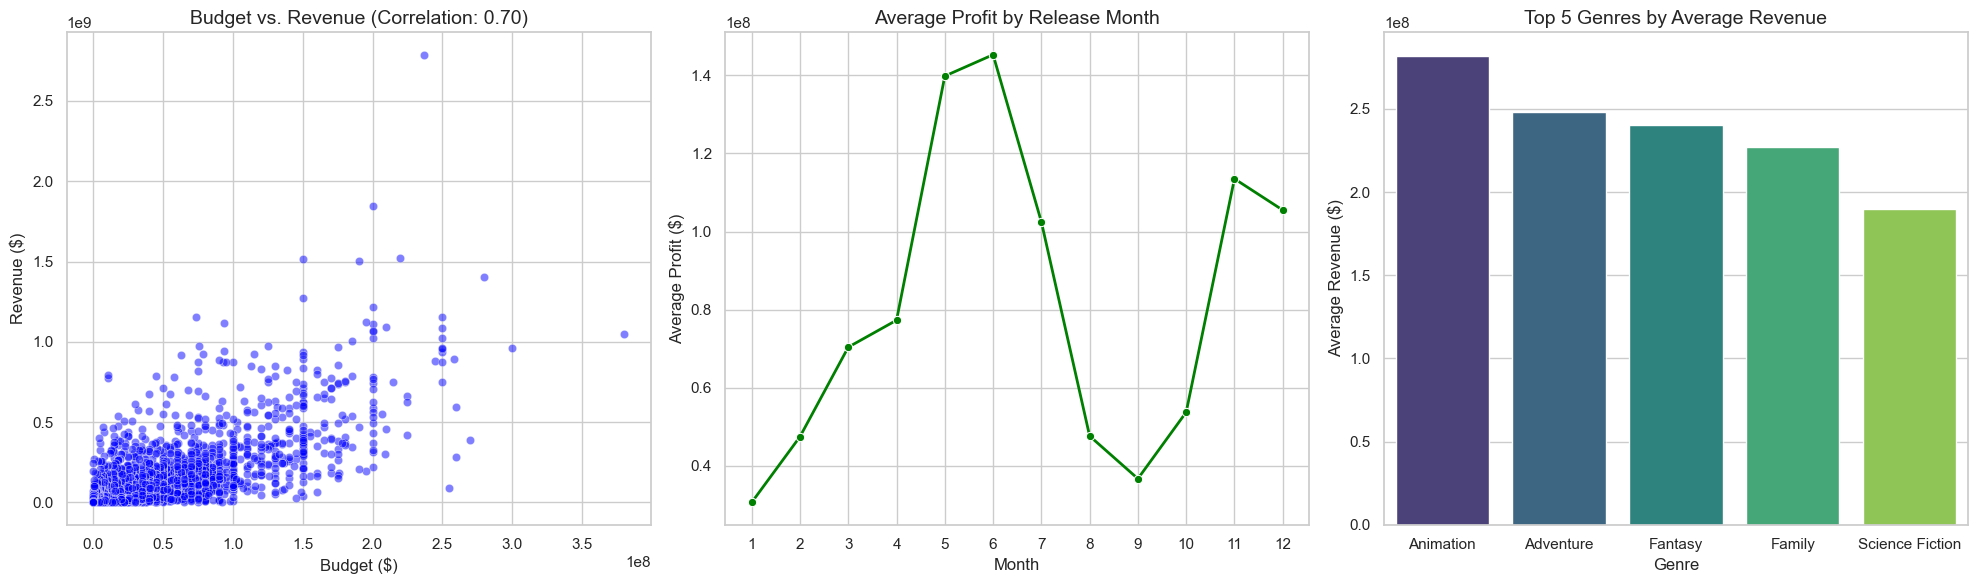

In [15]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# إعدادات الشكل العام للرسومات
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (14, 6)

conn = sqlite3.connect('tmdb_5000.db')
df_fin = pd.read_sql("SELECT * FROM clean_movies WHERE has_valid_financials = 1", conn)

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# 1. العلاقة بين الميزانية والإيرادات (Scatter Plot)
sns.scatterplot(data=df_fin, x='budget', y='revenue', alpha=0.5, color='blue', ax=axes[0])
axes[0].set_title('Budget vs. Revenue (Correlation: 0.70)', fontsize=14)
axes[0].set_xlabel('Budget ($)')
axes[0].set_ylabel('Revenue ($)')

# 2. متوسط الإيرادات حسب مواسم العرض (Line Chart)
season_data = df_fin.groupby('release_month')['profit'].mean().reset_index()
sns.lineplot(data=season_data, x='release_month', y='profit', marker='o', color='green', linewidth=2, ax=axes[1])
axes[1].set_title('Average Profit by Release Month', fontsize=14)
axes[1].set_xticks(range(1, 13))
axes[1].set_xlabel('Month')
axes[1].set_ylabel('Average Profit ($)')

# 3. توزيع الإيرادات لأكبر 5 تصنيفات (Bar Chart)
query_genres = """
SELECT g.genre_name, AVG(m.revenue) AS avg_revenue 
FROM clean_movies m JOIN movie_genres g ON m.id = g.movie_id
WHERE m.has_valid_financials = 1
GROUP BY g.genre_name ORDER BY avg_revenue DESC LIMIT 5;
"""
df_g = pd.read_sql(query_genres, conn)
sns.barplot(data=df_g, x='genre_name', y='avg_revenue', palette='viridis', ax=axes[2])
axes[2].set_title('Top 5 Genres by Average Revenue', fontsize=14)
axes[2].set_xlabel('Genre')
axes[2].set_ylabel('Average Revenue ($)')

plt.tight_layout()
plt.show()
conn.close()

In [17]:
import sqlite3
import pandas as pd
import os

# إنشاء مجلد لحفظ الملفات النظيفة
os.makedirs('PowerBI_Data', exist_ok=True)

conn = sqlite3.connect('tmdb_5000.db')

# سحب الجداول وتصديرها كملفات CSV
tables = ['clean_movies', 'movie_genres', 'movie_companies', 'movie_cast', 'movie_crew', 'movie_countries']

for table in tables:
    df = pd.read_sql(f"SELECT * FROM {table}", conn)
    df.to_csv(f'PowerBI_Data/{table}.csv', index=False)
    print(f"تم تصدير جدول {table} بنجاح.")

conn.close()
print("\n=== مبروك! الداتا جاهزة للـ Power BI في فولدر PowerBI_Data ===")

تم تصدير جدول clean_movies بنجاح.
تم تصدير جدول movie_genres بنجاح.
تم تصدير جدول movie_companies بنجاح.
تم تصدير جدول movie_cast بنجاح.
تم تصدير جدول movie_crew بنجاح.
تم تصدير جدول movie_countries بنجاح.

=== مبروك! الداتا جاهزة للـ Power BI في فولدر PowerBI_Data ===


In [1]:
import sqlite3
import pandas as pd

conn = sqlite3.connect('tmdb_5000.db')

# تصدير جدول الكلمات المفتاحية اللي نسيناه
df_keywords = pd.read_sql("SELECT * FROM movie_keywords", conn)
df_keywords.to_csv('PowerBI_Data/movie_keywords.csv', index=False)

conn.close()
print("تم تصدير جدول movie_keywords بنجاح.")

تم تصدير جدول movie_keywords بنجاح.
